# Valores y vectores propios: álgebra lineal y dinámica estructural

Te lo explico en dos partes: primero qué son en álgebra lineal y luego qué representan en dinámica estructural.

## 1. En álgebra lineal

Una matriz $\mathbf{A}$ transforma vectores: casi siempre los estira y además los gira. Los **vectores propios** son las direcciones especiales que la matriz solo estira, sin girarlas, y el **valor propio** es cuánto las estira:

$$\mathbf{A}\,\mathbf{v} = \lambda\,\mathbf{v}$$

- $\mathbf{A}$: la matriz, por ejemplo la de covarianza o la de rigidez.
- $\mathbf{v}$: el vector propio, la dirección que no gira.
- $\lambda$: el valor propio, el factor de estiramiento en esa dirección.

En palabras: al multiplicar la matriz por su vector propio, se obtiene el mismo vector multiplicado por un número.

En la figura, con datos de ejemplo, la matriz convierte un círculo en una elipse. El vector gris cambia de dirección, pero los dos vectores propios conservan la suya: uno se estira 3 veces y el otro 1 vez. Por eso los vectores propios son los ejes de la elipse.

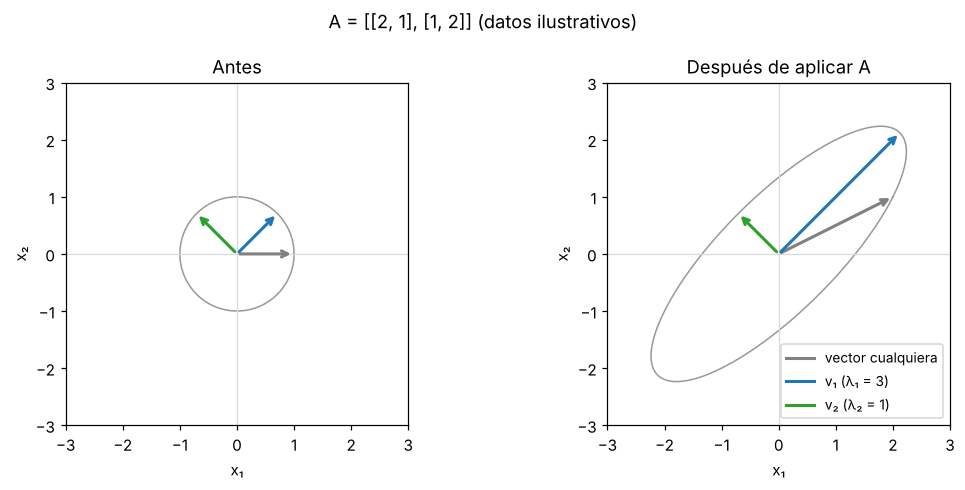

Eigenvalues: [1. 3.]
Eigenvectors (columns):
 [[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Example matrix (illustrative data)
A = np.array([[2.0, 1.0],
              [1.0, 2.0]])
eigvals, eigvecs = np.linalg.eigh(A)          # ascending: [1, 3]
v1, v2 = eigvecs[:, 1], eigvecs[:, 0]         # v1 -> lambda = 3, v2 -> lambda = 1
generic = np.array([1.0, 0.0])                # a generic vector (not an eigenvector)

theta = np.linspace(0, 2 * np.pi, 300)
circle = np.vstack([np.cos(theta), np.sin(theta)])
ellipse = A @ circle

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
panels = [("Antes", circle, generic, v1, v2),
          ("Después de aplicar A", ellipse, A @ generic, A @ v1, A @ v2)]
for ax, (title, curve, g, a, b) in zip(axes, panels):
    ax.plot(curve[0], curve[1], color="0.6", lw=1)
    for vec, color, label in [(g, "gray", "vector cualquiera"),
                              (a, "tab:blue", "v₁ (λ₁ = 3)"),
                              (b, "tab:green", "v₂ (λ₂ = 1)")]:
        ax.annotate("", xy=vec, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color=color, lw=2))
        ax.plot([], [], color=color, lw=2, label=label)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.axhline(0, color="0.85", lw=0.8); ax.axvline(0, color="0.85", lw=0.8)
    ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
axes[1].legend(loc="lower right", fontsize=9)
fig.suptitle("A = [[2, 1], [1, 2]] (datos ilustrativos)")
plt.tight_layout()
plt.show()

print("Eigenvalues:", eigvals)
print("Eigenvectors (columns):\n", eigvecs)

Por eso, en la matriz de covarianza, los vectores propios dan los ejes de la elipse de los datos y los valores propios, la varianza en cada eje. Es justo lo que usa el PCA.

## 2. En dinámica estructural

Se parte de la vibración libre sin amortiguamiento:

$$\mathbf{M}\ddot{\mathbf{u}} + \mathbf{K}\mathbf{u} = \mathbf{0}$$

- $\mathbf{M}$ y $\mathbf{K}$: las matrices de masa y de rigidez.
- $\mathbf{u}$ y $\ddot{\mathbf{u}}$: los vectores de desplazamientos y de aceleraciones.

La pregunta es si existe una forma en la que la estructura pueda vibrar sin deformarse distinto con el tiempo, es decir, con todos los puntos oscilando a la misma frecuencia. Se prueba con $\mathbf{u}(t) = \boldsymbol{\phi}\,\sin(\omega t)$, y eso da el problema de valores propios generalizado:

$$\mathbf{K}\,\boldsymbol{\phi} = \omega^2\,\mathbf{M}\,\boldsymbol{\phi}$$

- **Vector propio** $\boldsymbol{\phi}$: la **forma modal**, cómo se deforma la estructura en ese modo.
- **Valor propio** $\omega^2$: el **cuadrado de la frecuencia natural** circular de ese modo, en rad/s.

En palabras, los modos son las formas en las que la rigidez y la masa están en equilibrio dinámico. Si la estructura se deforma con esa forma, la fuerza elástica es exactamente proporcional a la fuerza de inercia, así que vibra sin cambiar de forma.

Por ejemplo, en un edificio de corte de 2 pisos con la misma masa $m$ y la misma rigidez $k$ en cada piso:

$$\omega_1^2 = 0.382\,\frac{k}{m},\ \ \boldsymbol{\phi}_1 = \begin{bmatrix}1\\1.618\end{bmatrix}; \qquad \omega_2^2 = 2.618\,\frac{k}{m},\ \ \boldsymbol{\phi}_2 = \begin{bmatrix}1\\-0.618\end{bmatrix}$$

En el primer modo, los dos pisos se mueven hacia el mismo lado y el de arriba se mueve más. En el segundo, se mueven en sentidos opuestos y la frecuencia es mayor.

In [2]:
from scipy.linalg import eigh

# Two-story shear building (m = k = 1, illustrative)
m, k = 1.0, 1.0
M = np.diag([m, m])
K = np.array([[2 * k, -k],
              [-k,     k]])

omega2, phi = eigh(K, M)           # generalized eigenproblem K phi = omega^2 M phi
phi = phi / phi[0, :]              # normalize so the first floor = 1

for i in range(2):
    print(f"Mode {i+1}: omega^2 = {omega2[i]:.3f} k/m, phi = {np.round(phi[:, i], 3)}")

Mode 1: omega^2 = 0.382 k/m, phi = [1.    1.618]
Mode 2: omega^2 = 2.618 k/m, phi = [ 1.    -0.618]


**Por qué es tan útil**

- **Superposición modal:** las formas modales son ortogonales respecto a la masa y a la rigidez. Por eso cualquier movimiento puede escribirse como suma de modos, y el sistema de $n$ grados de libertad acoplados se separa en $n$ osciladores de un grado de libertad independientes. Es la misma base del generador de señales.
- **Monitoreo de salud estructural:** el daño reduce $\mathbf{K}$, lo que baja los valores propios, es decir, las frecuencias, y deforma los vectores propios, es decir, las formas modales. Por eso se vigilan las frecuencias con z-score o Mahalanobis, y las formas modales con el MAC.
- **FDD:** la SVD de la matriz de PSD en un pico da la forma modal en su primer vector singular. Es otra descomposición de la misma familia, aplicada a datos medidos en lugar de a $\mathbf{M}$ y $\mathbf{K}$.